In [1]:
from modules import data_preprocessing as dataPrep

2026-09-14 14:20:17.057063: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
df = dataPrep.extract_kits23_shape()

Extracting Shapes:   0%|          | 0/489 [00:00<?, ?it/s]

Extracting Shapes: 100%|██████████| 489/489 [01:02<00:00,  7.81it/s]


In [7]:
for col in df.columns[1:]:
    # print(col)
    print(df[col].value_counts())

shape_z
97     11
103    11
96      9
98      7
101     7
       ..
454     1
190     1
202     1
256     1
248     1
Name: count, Length: 248, dtype: int64
shape_y
512    489
Name: count, dtype: int64
shape_x
512    486
796      1
651      1
632      1
Name: count, dtype: int64


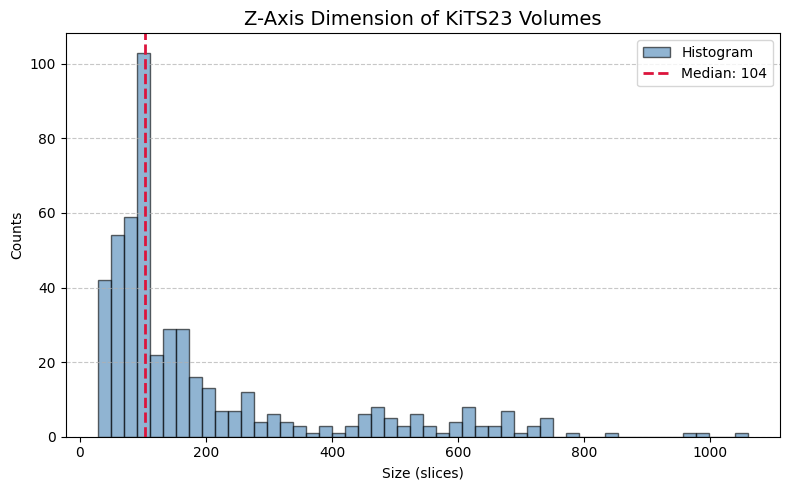

In [12]:
import os
import matplotlib.pyplot as plt
import numpy as np

median_z = np.ceil(df["shape_z"].median()).astype(int)

data = df["shape_z"].dropna()

plt.figure(figsize=(8, 5))

plt.hist(
    data,
    bins=50,
    alpha=0.6,
    color="steelblue",
    edgecolor="black",
    label="Histogram",
)

plt.axvline(
    median_z,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_z}",
)

plt.title("Z-Axis Dimension of KiTS23 Volumes", fontsize=14)
plt.xlabel("Size (slices)")
plt.ylabel("Counts")
plt.legend(loc="upper right")
plt.grid(axis="y", linestyle="--", alpha=0.7)

os.makedirs("figures", exist_ok=True)
plt.tight_layout()
plt.savefig("figures/kits23_shape_z.png", dpi=300, bbox_inches="tight")
plt.show()